# 05 · Gaussian processes

*Level: intermediate. Guide Section 9. Code: `models.GP` (scikit-learn), `structured.HierGP` (PyTorch, extended in 09).*

**Idea.** A GP predicts at new inputs by averaging the examples it has seen, weighted by how **similar** their inputs are.
* Far from all examples, it falls back to the average and its error bar grows.
* It learns, for every input, how far "similar" reaches, so inputs that do not matter get ignored.

In [1]:
from tutorial_utils import *

## 1. The kernel: similarity between two inputs

The Matérn-5/2 kernel:

$$k(x, x') = \sigma_f^2\left(1 + \sqrt5 r + \tfrac53 r^2\right)e^{-\sqrt5 r},\qquad r = |x - x'|/\ell .$$

* $\sigma_f^2$ is the signal variance;
* $\ell$ is the **length scale**, i.e. how far apart two inputs can be and still give similar values.

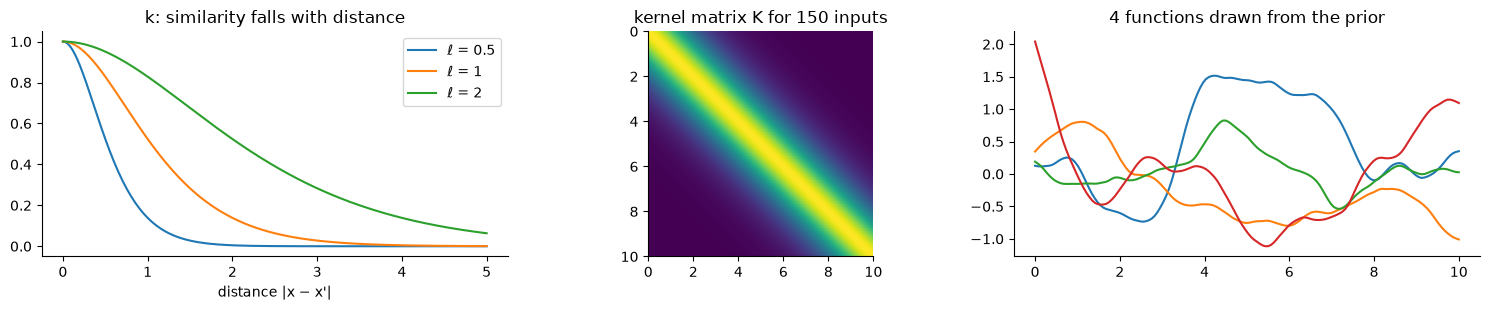

In [2]:
def matern52(a, b, ell=1.0, sf2=1.0):
    r = np.abs(a[:, None] - b[None, :]) / ell
    return sf2 * (1 + np.sqrt(5) * r + 5 / 3 * r ** 2) * np.exp(-np.sqrt(5) * r)

d = np.linspace(0, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for ell in (0.5, 1, 2):
    ax[0].plot(d, matern52(np.array([0.0]), d, ell)[0], label=f"ℓ = {ell}")
ax[0].legend(); ax[0].set_xlabel("distance |x − x'|"); ax[0].set_title("k: similarity falls with distance")
xg = np.linspace(0, 10, 150); K = matern52(xg, xg, 1.5)
ax[1].imshow(K, extent=[0, 10, 10, 0]); ax[1].set_title("kernel matrix K for 150 inputs")
L = np.linalg.cholesky(K + 1e-8 * np.eye(len(xg)))
for s in range(4):
    ax[2].plot(xg, L @ np.random.default_rng(s).normal(size=len(xg)))
ax[2].set_title("4 functions drawn from the prior"); plt.tight_layout(); plt.show()

Drawing from the prior uses the **Cholesky factor** $L$ ($K = LL^\top$): if $\mathbf z$ is standard normal, $L\mathbf z$ has covariance $K$.

## 2. The posterior, by hand

With noisy observations $y_i = f(x_i) + \varepsilon_i$, $\varepsilon_i \sim \mathcal N(0, \sigma_n^2)$, the prediction at $x_*$ is

$$\mu(x_*) = \mathbf k_*^\top (K + \sigma_n^2 I)^{-1}\mathbf y,\qquad s^2(x_*) = k_{**} - \mathbf k_*^\top (K + \sigma_n^2 I)^{-1}\mathbf k_* ,$$

* $K$: the kernel matrix of the training inputs;
* $\mathbf k_*$: the kernel between $x_*$ and every training input;
* $k_{**} = k(x_*, x_*)$.

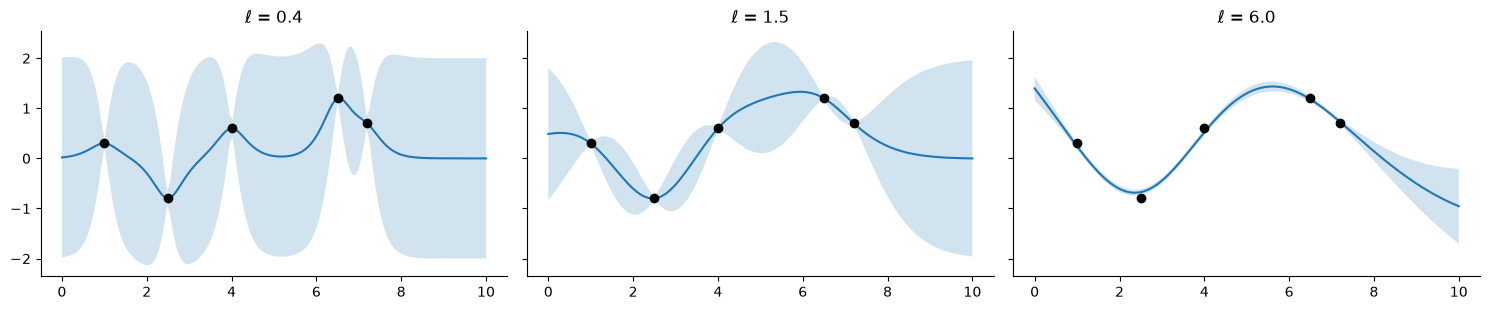

In [3]:
x = np.array([1.0, 2.5, 4.0, 6.5, 7.2]); y = np.array([0.3, -0.8, 0.6, 1.2, 0.7]); sn2 = 1e-3
def posterior(x, y, xs, ell, sf2=1.0, sn2=1e-3):
    K = matern52(x, x, ell, sf2) + sn2 * np.eye(len(x)); Ks = matern52(xs, x, ell, sf2)
    L = np.linalg.cholesky(K)
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y))          # (K + σn² I)⁻¹ y via two triangular solves
    v = np.linalg.solve(L, Ks.T)
    return Ks @ alpha, np.sqrt(np.clip(sf2 - (v * v).sum(0), 0, None))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for a, ell in zip(ax, (0.4, 1.5, 6.0)):
    mu, s = posterior(x, y, xg, ell)
    a.fill_between(xg, mu - 2 * s, mu + 2 * s, alpha=0.2); a.plot(xg, mu); a.scatter(x, y, color="k", zorder=3); a.set_title(f"ℓ = {ell}")
plt.tight_layout(); plt.show()

## 3. Choosing ℓ: the log marginal likelihood

$$\log p(\mathbf y) = \underbrace{-\tfrac12\mathbf y^\top K_y^{-1}\mathbf y}_\text{data fit} \underbrace{-\tfrac12\log\det K_y}_\text{complexity penalty} - \tfrac n2\log 2\pi,\qquad K_y = K + \sigma_n^2 I.$$

* A short $\ell$ fits anything, so the data-fit term is good but the penalty is large.
* A long $\ell$ is simple but fits badly.

Maximizing the sum is an automatic Occam's razor. Here it is evaluated on 25 noisy points of a known function.

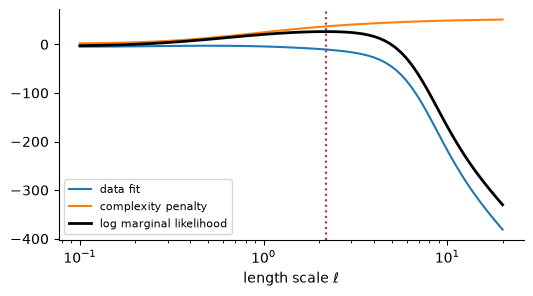

best ℓ = 2.19


In [4]:
rng = np.random.default_rng(2)
x2 = np.sort(rng.uniform(0, 10, 25)); y2 = np.sin(x2) + 0.1 * rng.normal(size=25)
ells = np.geomspace(0.1, 20, 80); fit_, pen_ = [], []
for ell in ells:
    Ky = matern52(x2, x2, ell) + 0.01 * np.eye(25); L = np.linalg.cholesky(Ky)
    a = np.linalg.solve(L.T, np.linalg.solve(L, y2))
    fit_.append(-0.5 * y2 @ a); pen_.append(-np.sum(np.log(np.diag(L))))   # log det K_y = 2 Σ log L_ii
lml = np.array(fit_) + np.array(pen_)
plt.figure(figsize=(6, 3)); plt.semilogx(ells, fit_, label="data fit"); plt.semilogx(ells, pen_, label="complexity penalty")
plt.semilogx(ells, lml, "k", lw=2, label="log marginal likelihood"); plt.axvline(ells[np.argmax(lml)], color="C3", ls=":")
plt.legend(fontsize=8); plt.xlabel("length scale ℓ"); plt.show()
print(f"best ℓ = {ells[np.argmax(lml)]:.2f}")

## 4. One length scale per input (ARD): finding what matters

With two inputs where only $x_1$ matters, the fitted length scale of $x_2$ grows large, so $x_2$ is effectively ignored. Relevance = $1/\ell$.

In [5]:
X2 = rng.uniform(0, 1, (120, 2)); y3 = np.sin(6 * X2[:, 0]) + 0.05 * rng.normal(size=120)
gp = models.GP().fit(X2, y3[:, None])
print("fitted length scales (inputs standardized): x1 =", gp.length_scales()[0].round(2), " x2 =", gp.length_scales()[1].round(1))

fitted length scales (inputs standardized): x1 = 1.48  x2 = 1000.0


## 5. On the toy CCD: which settings matter for one amplifier?

The GP is fitted on the 10 settings for amplifier 0 only. Its relevances show which knobs move σe and which move λ.

GP on the settings (amplifier 0)         sigma_e:  19.7 % (cover 0.72)   lambda:  13.9 % (cover 0.65)   gain:   0.9 % (cover 0.65)


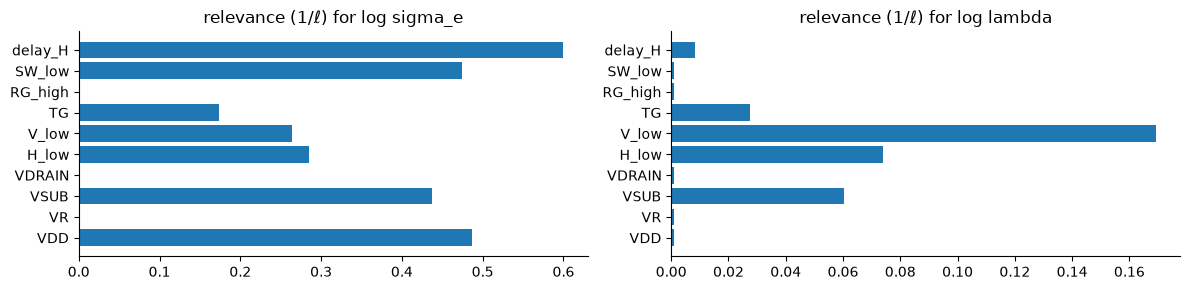

In [6]:
df, curves, Y, groups = toy_scan(120, seed=1)
one = (df.channel == 0).to_numpy()
Xs, names = data.make_inputs(df[one], ("theta",), drop_constant=False)
mean, std = grouped_cv(lambda: models.GP(), Xs, Y[one], groups[one])
_ = report("GP on the settings (amplifier 0)", Y[one], mean, std)
g = models.GP().fit(Xs, Y[one])
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for a, t in zip(ax, (0, 1)):
    a.barh([n.split(".")[1] for n in names], 1 / g.length_scales(t)); a.set_title(f"relevance (1/ℓ) for log {TARGETS[t]}")
plt.tight_layout(); plt.show()

## When to use it

* **Good:** small data (tens to ~1000 examples); honest error bars; Bayesian optimization (06); reading off what matters.
* **Bad:** many thousands of rows (cost grows as $n^3$); very many inputs, because one length scale each can over-fit.

Next: **06 · Bayesian optimization.**